# Fig. 4: Bayesian optimisation (BO) of the PAA control parameters.

- (a) Sobol indices (total and first order) of the 7 BO parameters.
- (b) Partial-dependence contours of mean yield for 3 parameter pairs.
- (c) Yield on the 200 evaluation batches.
- (d) F_PAA trajectories and (e) PAA trajectories over batch progress.
A GP is fitted to all BO evaluations (bo_paa_log_patch_s{0..9}.json); Sobol indices and
partial dependence are computed on the GP and cached in fig4_gp_cache.npz.
Evaluation batches (200): no intervention = ybase in testset_fig5_REPORTONLY_random200.npz,
APC = y_apcA in apc_streamA_b5_v2.npz, BO = per-batch mean over 10 runs of
fin_boctrl_patch_s{0..9}_rand200_yield.npy. Trajectories: traj_b5v6.npz (no intervention,
APC) and traj_b5_bo_patch_s{0..9}.npz (BO, per-batch mean over 10 runs) on a 200-point
batch-progress grid.
- (c) dot = mean, error bar = batch-bootstrap 95 % interval. (d)(e) line = mean over 200
batches, band = 95 % interval (1.96 SE).

In [1]:
import sys; sys.path.insert(0, '..')          # repository root, for paths.py
from paths import DATA, OUTD                   # data/ and output/

In [2]:
import os, json, numpy as np, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.colors import LinearSegmentedColormap
G = DATA; R = DATA
OUT = OUTD + 'fig4'; CACHE = OUTD + 'fig4_gp_cache.npz'   # computed on the first run
INK, GRY = '#23201a', '#8f897d'
C_BASE, C_APC, C_BO = GRY, '#8a3324', '#2a7f7a'                                   # arm colours shared with other figures; BO in teal
cm = LinearSegmentedColormap.from_list('br', ['#46618a', '#d9d4ca', '#a35a3c'])
plt.rcParams.update({'font.family': ['DejaVu Sans'], 'font.size': 5.5, 'axes.titlesize': 6.5, 'axes.labelsize': 5.5,
                     'xtick.labelsize': 5.0, 'ytick.labelsize': 5.0, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'legend.fontsize': 5.0,
                     'mathtext.default': 'regular'})
NAMES = ['SP1', 'SP2', 't_switch', 't_start', 'kappa', 'm_s', 't_s']
SYM = ['SP$_1$', 'SP$_2$', '$t_{switch}$', '$t_{start}$', '$\\kappa$', '$m_s$', '$t_s$']
LAB = {0: 'SP$_1$ (mg L$^{-1}$)', 1: 'SP$_2$ (mg L$^{-1}$)', 2: '$t_{switch}$ (h)'}
LO = np.array([600, 200, 40, 10, 0.3, 1.0, 60]); HI = np.array([1800, 1600, 220, 80, 3.0, 1.001, 220])
def th(u):
    t = LO + u * (HI - LO); t[..., 4] = LO[4] * (HI[4] / LO[4]) ** u[..., 4]; return t
U, BEST = [], []
for s in range(10):
    d = json.load(open(R + f'bo_paa_log_patch_s{s}.json')); U += [e['u'] for e in d]; BEST.append(max(d, key=lambda e: e['y'])['u'])
U, BEST = np.array(U), np.array(BEST)
PAIRS = [(1, 2), (1, 0), (2, 0)]                                                  # (x, y): SP2×t_switch · SP2×SP1 · t_switch×SP1
if not os.path.exists(CACHE):
    from sklearn.gaussian_process import GaussianProcessRegressor as GPR
    from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel as C
    Y = np.array([e['y'] for s in range(10) for e in json.load(open(R + f'bo_paa_log_patch_s{s}.json'))])
    gp = GPR(C(1.0) * Matern(length_scale=np.ones(7), nu=2.5, length_scale_bounds=(1e-2, 1e2)) + WhiteKernel(1e-2, (1e-6, 1)),
             normalize_y=True, n_restarts_optimizer=3, random_state=0).fit(U, Y)
    rng = np.random.default_rng(0); N, d = 8192, 7
    A, B = rng.random((N, d)), rng.random((N, d)); fA, fB = gp.predict(A), gp.predict(B)
    fAB = np.array([gp.predict(np.where(np.arange(d) == i, B, A)) for i in range(d)])
    def sob(ix):
        a, b, ab = fA[ix], fB[ix], fAB[:, ix]; V = np.var(np.concatenate([a, b]))
        return np.mean(b * (ab - a), 1) / V, 0.5 * np.mean((a - ab) ** 2, 1) / V
    S1, ST = sob(np.arange(N)); bs = [sob(rng.integers(0, N, N)) for _ in range(300)]
    S1c = np.percentile([x[0] for x in bs], [2.5, 97.5], 0); STc = np.percentile([x[1] for x in bs], [2.5, 97.5], 0)
    base = rng.random((300, d)); ng = 25; g = np.linspace(0, 1, ng); PD = []
    for (j, i) in PAIRS:
        M = np.zeros((ng, ng))
        for a_, vj in enumerate(g):
            Bj = base.copy(); Bj[:, j] = vj
            for b_, vi in enumerate(g):
                Bi = Bj.copy(); Bi[:, i] = vi; M[b_, a_] = gp.predict(Bi).mean()
        PD.append(M)
    np.savez(CACHE, S1=S1, ST=ST, S1c=S1c, STc=STc, PD=np.array(PD), g=g)
K = np.load(CACHE); S1, ST, S1c, STc, PD, g = K['S1'], K['ST'], K['S1c'], K['STc'], K['PD'], K['g']
# evaluation batches
tb = np.load(G + 'testset_fig5_REPORTONLY_random200.npz'); v6 = np.load(G + 'traj_b5v6.npz'); FR = v6['frac']
YL = {'No intervention': tb['ybase'].astype(float), 'APC': np.load(G + 'apc_streamA_b5_v2.npz', allow_pickle=True)['y_apcA'].astype(float),
      'BO-tuned controller': np.mean([np.load(G + f'fin_boctrl_patch_s{s}_rand200_yield.npy') for s in range(10)], 0)}
BOT = [np.load(G + f'traj_b5_bo_patch_s{s}.npz') for s in range(10)]
TR = {v: {'No intervention': v6[f'base_{v}'], 'APC': v6[f'apc_{v}'], 'BO-tuned controller': np.nanmean([z[f'bo_{v}'] for z in BOT], 0)} for v in ('Fpaa_u', 'PAA')}
COL = {'No intervention': C_BASE, 'APC': C_APC, 'BO-tuned controller': C_BO}; LS = {'No intervention': (0, (3, 2.2)), 'APC': '-', 'BO-tuned controller': '-'}
def style(a):
    for sp in ('top', 'right'): a.spines[sp].set_visible(False)
    for sp in ('left', 'bottom'): a.spines[sp].set_color(INK)
    a.tick_params(colors=INK)
def title(a, s, x=None): a.set_title(s, loc='left', fontweight='bold', color=INK, pad=4, **({} if x is None else dict(x=x)))
fig = plt.figure(figsize=(17 / 2.54, 11 / 2.54), facecolor='white')
gs = GridSpec(2, 2, figure=fig, width_ratios=[0.58, 1.42], height_ratios=[1, 1], wspace=0.24, hspace=0.50,
              left=0.07, right=0.94, top=0.95, bottom=0.10)

In [3]:
# (a) Sobol
aa = fig.add_subplot(gs[0, 0]); style(aa); o = np.argsort(-ST); yy = np.arange(7)
aa.barh(yy - 0.18, ST[o], height=0.34, color=INK, label='Total')
aa.barh(yy + 0.18, S1[o], height=0.34, color=GRY, label='First order')
aa.errorbar(ST[o], yy - 0.18, xerr=[ST[o] - STc[0][o], STc[1][o] - ST[o]], fmt='none', ecolor=INK, elinewidth=0.5, capsize=1)
aa.errorbar(np.clip(S1[o], 0, None), yy + 0.18, xerr=[np.clip(S1[o], 0, None) - np.clip(S1c[0][o], 0, None), S1c[1][o] - np.clip(S1[o], 0, None)],
            fmt='none', ecolor=INK, elinewidth=0.5, capsize=1)
aa.set_yticks(yy); aa.set_yticklabels([SYM[i] for i in o], color=INK); aa.invert_yaxis(); aa.tick_params(axis='y', length=0)
aa.set_xlabel('Sobol index', color=INK); aa.set_xlim(0, 1.0); aa.legend(loc='lower right', frameon=False, handlelength=1.2)
title(aa, '(a)')

In [4]:
# (b) Partial-dependence contours for 3 pairs
sub = GridSpecFromSubplotSpec(1, 4, subplot_spec=gs[0, 1], wspace=0.55, width_ratios=[1, 1, 1, 0.06])
vmin, vmax = PD.min(), PD.max(); LEVS = np.linspace(vmin, vmax, 15); tU, tB = th(U), th(BEST)
axv = lambda i: LO[i] + g * (HI[i] - LO[i])
SWAP = [True, False, False]                                                     # first panel: x = t_switch, y = SP2 (cached PD is transposed)
for k, (j, i) in enumerate(PAIRS):
    M = PD[k].T if SWAP[k] else PD[k]
    if SWAP[k]: j, i = i, j
    a = fig.add_subplot(sub[k]); style(a)
    cf = a.contourf(axv(j), axv(i), M, levels=LEVS, cmap=cm)
    a.scatter(tU[:, j], tU[:, i], s=0.6, c=GRY, lw=0, alpha=.6)
    a.scatter(tB[:, j], tB[:, i], s=6, facecolors='none', edgecolors=INK, lw=0.5)
    a.set_xlim(LO[j], HI[j]); a.set_ylim(LO[i], HI[i]); a.set_xlabel(LAB[j], color=INK)
    a.set_ylabel(LAB[i], color=INK, labelpad=1)                                # y label and ticks on all three panels
    if k == 0: title(a, '(b)')
cb = fig.colorbar(cf, cax=fig.add_subplot(sub[3])); cb.outline.set_visible(False)
cb.set_label('Mean yield (kg)', color=INK); cb.ax.tick_params(labelsize=4.6, colors=INK, length=1.5); cb.set_ticks(np.arange(np.ceil(vmin / 500) * 500, vmax + 1, 500))                # ticks within range only

In [5]:
# (c) Yield, (d) F_PAA, (e) PAA
sub2 = GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[1, :], wspace=0.38, width_ratios=[0.62, 1, 1])
ac = fig.add_subplot(sub2[0]); style(ac); rb = np.random.default_rng(0)
for x, (nm, y) in enumerate(YL.items()):
    bs = y[rb.integers(0, len(y), (5000, len(y)))].mean(1); lo, hi = np.percentile(bs, [2.5, 97.5])
    ac.errorbar(x, y.mean(), yerr=[[y.mean() - lo], [hi - y.mean()]], fmt='o', ms=3.4, mfc=COL[nm], mec=COL[nm],
                ecolor=COL[nm], elinewidth=0.9, capsize=0)                      # dot + 95 % interval instead of a bar, since the axis does not start at 0
ac.set_xticks(range(3)); ac.set_xticklabels(['No\nintervention', 'APC', 'BO-tuned\ncontroller'], color=INK)
ac.tick_params(axis='x', length=0); ac.set_xlim(-0.5, 2.5); ac.set_ylim(2600, 3800); ac.set_ylabel('Penicillin yield (kg)', color=INK); title(ac, '(c)')
for k, (v, ylab, let) in enumerate((('Fpaa_u', '$F_{PAA}$ (L h$^{-1}$)', '(d)'), ('PAA', 'PAA (mg L$^{-1}$)', '(e)'))):
    a = fig.add_subplot(sub2[1 + k]); style(a)
    for nm, A in TR[v].items():
        A = A[np.isfinite(A).all(1)]; m = A.mean(0); se = A.std(0, ddof=1) / np.sqrt(len(A))
        a.fill_between(FR * 100, m - 1.96 * se, m + 1.96 * se, color=COL[nm], alpha=.18, lw=0)
        a.plot(FR * 100, m, color=COL[nm], ls=LS[nm], lw=0.9, label=nm)
    if v == 'PAA': a.axhline(2400, color=INK, lw=0.4, ls=(0, (1, 1.2)))
    a.set_xlim(0, 100); a.set_xlabel('Batch time (% of batch duration)', color=INK); a.set_ylabel(ylab, color=INK); title(a, let)
    if k == 1: a.legend(loc='upper left', frameon=False, handlelength=1.8)
for ext, kw in (('png', dict(dpi=600)), ('pdf', {})):
    fig.savefig(f'{OUT}.{ext}', facecolor='white', **kw)
print('saved', OUT)
b = YL['BO-tuned controller']
for ref in ('No intervention', 'APC'):
    d = b - YL[ref]; bs = d[rb.integers(0, 200, (5000, 200))].mean(1); print(f'  BO − {ref}: {d.mean():+.0f} [{np.percentile(bs, 2.5):+.0f}, {np.percentile(bs, 97.5):+.0f}] kg')
print('  mean yield', {k: round(v.mean()) for k, v in YL.items()})
for v in TR: print(' ', v, {k: (round(float(np.nanmean(A)), 1), round(float(np.nanmax(np.nanmean(A, 0))), 1)) for k, A in TR[v].items()})

saved ../output/fig4
  BO − No intervention: +851 [+748, +956] kg
  BO − APC: +183 [+145, +216] kg
  mean yield {'No intervention': 2800, 'APC': 3467, 'BO-tuned controller': 3650}
  Fpaa_u {'No intervention': (8.4, 10.3), 'APC': (7.0, 9.0), 'BO-tuned controller': (7.1, 9.5)}
  PAA {'No intervention': (1936.8, 4625.7), 'APC': (1226.4, 1589.9), 'BO-tuned controller': (1071.4, 1589.9)}


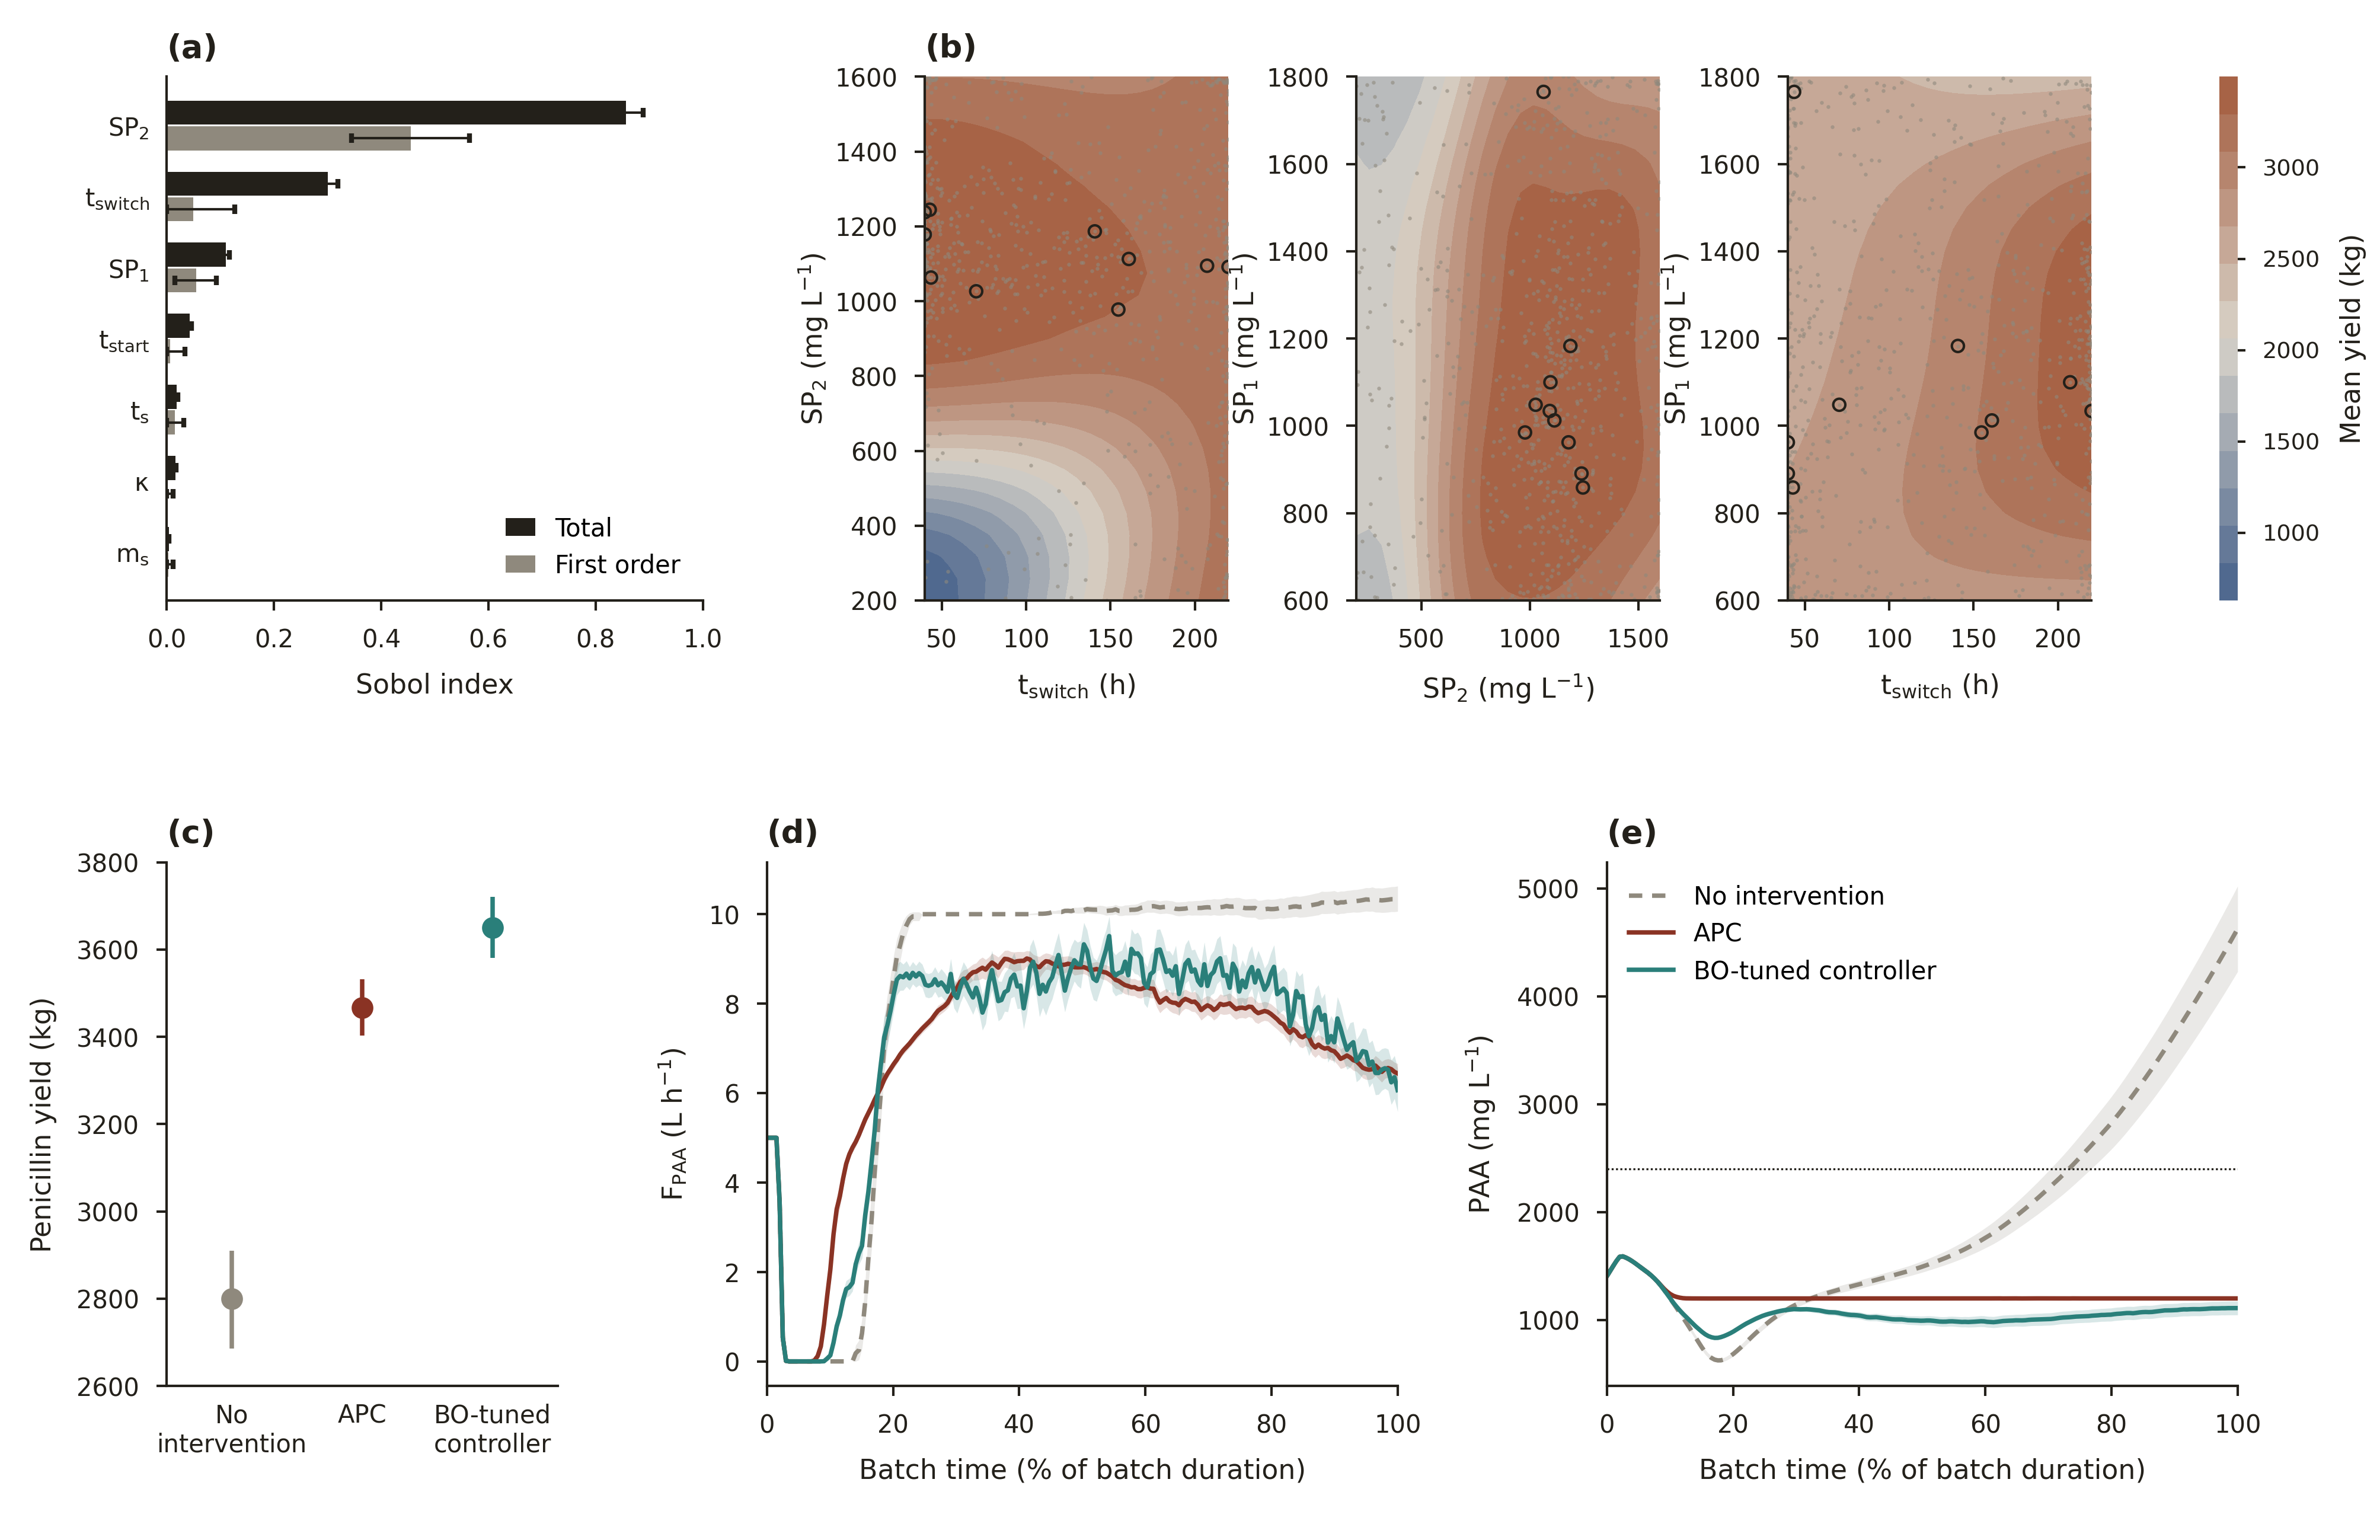

In [6]:
from IPython.display import Image
Image(OUTD + 'fig4.png', width=900)